In [2]:
!pip install tensorflow matplotlib numpy scikit-learn pillow

Defaulting to user installation because normal site-packages is not writeable


# 1. Import all libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

print("TensorFlow Version:", tf.__version__)
print("CNN project started successfully!")

TensorFlow Version: 2.21.0
CNN project started successfully!


# 2. Define your dataset paths

In [2]:
# Main dataset folder
DATASET_PATH = r"C:\Users\Tamilarasan\anaconda_projects\Proitpridge Study\DL\07 Chapter_11.2 CNN For External Data (Real Time) Classification Problem"

# Three separate folders
TRAIN_DIR = os.path.join(DATASET_PATH, "train_data")
VAL_DIR = os.path.join(DATASET_PATH, "val_data")
TEST_DIR = os.path.join(DATASET_PATH, "test_data")

# Check whether the folders exist
print("Train folder exists:", os.path.exists(TRAIN_DIR))
print("Validation folder exists:", os.path.exists(VAL_DIR))
print("Test folder exists:", os.path.exists(TEST_DIR))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# 3. Load the images

In [3]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 4
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 50 files belonging to 5 classes.
Found 10 files belonging to 5 classes.
Found 15 files belonging to 5 classes.
Classes: ['ak', 'dhanush', 'hip_hop', 'sk', 'vijay']
Number of classes: 5


In [4]:
print("Training classes:", train_ds.class_names)
print("Validation classes:", val_ds.class_names)
print("Testing classes:", test_ds.class_names)

assert train_ds.class_names == val_ds.class_names == test_ds.class_names, \
    "Error: Class folder names or class ordering do not match!"

Training classes: ['ak', 'dhanush', 'hip_hop', 'sk', 'vijay']
Validation classes: ['ak', 'dhanush', 'hip_hop', 'sk', 'vijay']
Testing classes: ['ak', 'dhanush', 'hip_hop', 'sk', 'vijay']


# 4. Display sample images

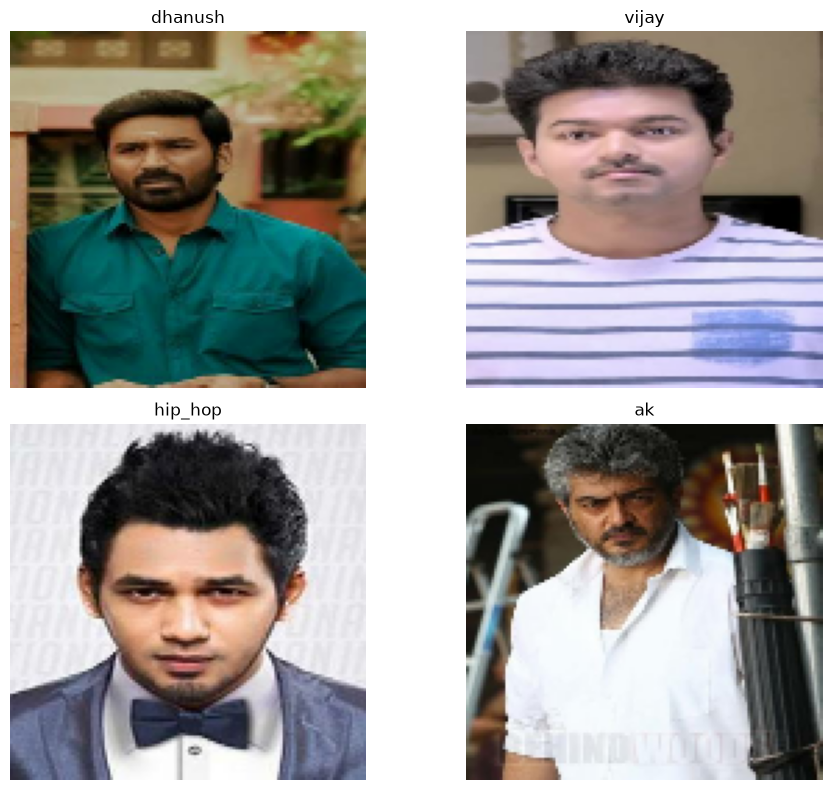

In [5]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(len(images)):
        plt.subplot(2, 2, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

# 5. Normalize the image pixels

In [6]:
normalization_layer = layers.Rescaling(1.0 / 255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

# Improve input pipeline performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Images normalized successfully!")

Images normalized successfully!


# 6. Build your CNN architecture from scratch

In [82]:
NUM_CLASSES = len(class_names)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Feature extraction
    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Final output: one probability per class
    layers.Dense(NUM_CLASSES, activation="softmax")
])
model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_27 (Conv2D)                   │ (None, 128, 128, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_28 (Conv2D)                   │ (None, 64, 64, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_29 (Conv2D)                   │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_7 (Flatten)                  │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 64)                  │       1,048,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,072,549 (4.09 MB)

 Trainable params: 1,072,549 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

# 7. Understand the CNN architecture

Input image
128 × 128 × 3

Conv2D — 16 filters
Detects basic edges and patterns

MaxPooling
Reduces spatial dimensions

Conv2D — 32 and 64 filters
Learns more complex image features

Flatten → Dense → Dropout
Uses extracted features for classification

Softmax output
Predicts one of your five classes

# 8. Compile the model

In [84]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_27 (Conv2D)                   │ (None, 128, 128, 16)        │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_21 (MaxPooling2D)      │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_28 (Conv2D)                   │ (None, 64, 64, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_22 (MaxPooling2D)      │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_29 (Conv2D)                   │ (None, 32, 32, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_23 (MaxPooling2D)      │ (None, 16, 16, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_7 (Flatten)                  │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 64)                  │       1,048,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,072,549 (4.09 MB)

 Trainable params: 1,072,549 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

# 9.Train the CNN model

In [85]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    mode="min"
)

In [86]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    # callbacks=[early_stopping]
)

Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.1600 - loss: 2.3299 - val_accuracy: 0.2000 - val_loss: 1.6227
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2000 - loss: 1.6308 - val_accuracy: 0.1000 - val_loss: 1.6159
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2600 - loss: 1.5989 - val_accuracy: 0.2000 - val_loss: 1.6053
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.2400 - loss: 1.6055 - val_accuracy: 0.3000 - val_loss: 1.5949
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3200 - loss: 1.5679 - val_accuracy: 0.3000 - val_loss: 1.5970
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4600 - loss: 1.4544 - val_accuracy: 0.2000 - val_loss: 1.6358
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5600 - loss: 1.2352 - val_accuracy: 0.4000 - val_loss: 1.6088
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6200 - loss: 1.1336 - val_accuracy: 0.4000 - v

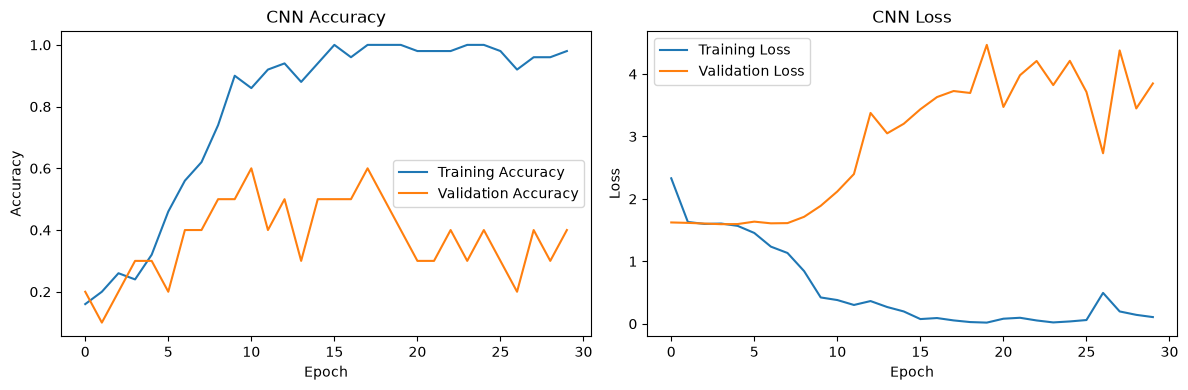

In [87]:
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [88]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2000 - loss: 4.9517 
Test Loss: 4.9517
Test Accuracy: 20.00%


In [89]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

          ak       0.00      0.00      0.00         3
     dhanush       0.40      0.67      0.50         3
     hip_hop       0.25      0.33      0.29         3
          sk       0.00      0.00      0.00         3
       vijay       0.00      0.00      0.00         3

    accuracy                           0.20        15
   macro avg       0.13      0.20      0.16        15
weighted avg       0.13      0.20      0.16        15



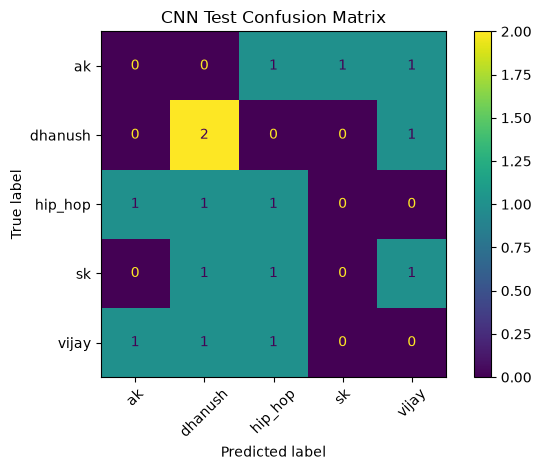

In [90]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(xticks_rotation=45, values_format="d")
plt.title("CNN Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [91]:
model.save("human_cnn_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [92]:
loaded_model = tf.keras.models.load_model("human_cnn_model.keras")
print("Saved model loaded successfully!")

Saved model loaded successfully!


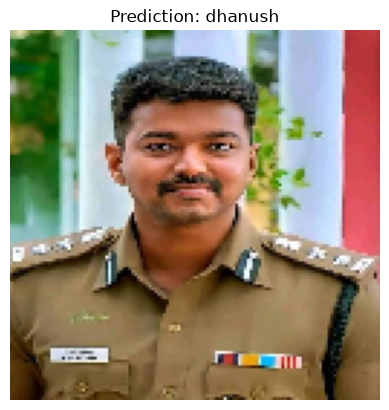

Predicted Class: dhanush
Model Confidence: 98.26%


In [93]:
IMAGE_PATH = r"C:\Users\Tamilarasan\anaconda_projects\Proitpridge Study\DL\07 Chapter_11.2 CNN For External Data (Real Time) Classification Problem\test_data\vijay\images (13).jpeg"

# Load and resize image
img = image.load_img(
    IMAGE_PATH,
    target_size=(128, 128)
)

# Convert image to array
img_array = image.img_to_array(img)

# Normalize pixels to 0–1
img_array = img_array / 255.0

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = loaded_model.predict(img_array, verbose=0)

predicted_index = np.argmax(prediction[0])
predicted_class = class_names[predicted_index]
confidence = prediction[0][predicted_index] * 100

plt.imshow(img)
plt.axis("off")
plt.title(f"Prediction: {predicted_class}")
plt.show()

print("Predicted Class:", predicted_class)
print(f"Model Confidence: {confidence:.2f}%")

# THE END !!! 